In [1]:
%pip install opencv-python-headless matplotlib scipy tqdm ipywidgets widgetsnbextension

  Using cached ipywidgets-8.1.7-py3-none-any.whl.metadata (2.4 kB)
  Using cached widgetsnbextension-4.0.14-py3-none-any.whl.metadata (1.6 kB)
  Using cached jupyterlab_widgets-3.0.15-py3-none-any.whl.metadata (20 kB)
Using cached ipywidgets-8.1.7-py3-none-any.whl (139 kB)
Using cached widgetsnbextension-4.0.14-py3-none-any.whl (2.2 MB)
Using cached jupyterlab_widgets-3.0.15-py3-none-any.whl (216 kB)

   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   ---------------------------------------- 3/3 [ipywidgets]

Note: you may need to restart the kernel to use updated packages.


In [2]:
from glob import glob

import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from tqdm.notebook import tqdm

In [3]:
DATASET_MASK = "./dataset/trypsin_3s_2021/*.JPG"

In [4]:
images = glob(DATASET_MASK)

In [5]:
image_np = cv2.imread(images[50])
image_np = cv2.cvtColor(image_np, cv2.COLOR_BGR2GRAY)
image_np.shape

(2000, 3000)

In [6]:
def moving_average(x, w):
    x_padded = np.pad(x, (w//2, w-1-w//2), mode='edge')
    return np.convolve(x_padded, np.ones(w), 'valid') / w

In [7]:
def find_nearests(value, array, threshold):
    dists = np.linalg.norm(array - value, axis=1)
    return np.argwhere(dists < threshold)


def bubble_sort(arr, threshold):
    def compare(x, y):
        if np.abs(x[1] - y[1]) < threshold:
            return x[0] > y[0]
        else:
            return x[1] > y[1]
    n = len(arr)
    for i in range(n - 1):
        for j in range(0, n - i - 1):
            if compare(arr[j], arr[j + 1]):
                arr[j], arr[j + 1] = arr[j + 1], arr[j]
    return arr

def merge_nearests(array, threshold):
    merged = []
    merged_array = []
    for i in range(array.shape[0]):
        if i in merged:
            continue
        nearests = find_nearests(array[i], array, threshold)
        merged.extend(nearests)
        merged_array.append(array[nearests].mean(axis=0)[0])

    
    merged_array = bubble_sort(merged_array, threshold)
    
    return np.squeeze(np.array(merged_array))


def find_wells(image_np: np.ndarray, 
               n_wells_x = 8,
               n_wells_y = 5,
               threshold:int=50):
    circles = cv2.HoughCircles(
        image_np, cv2.HOUGH_GRADIENT_ALT,
        dp=2,
        minDist=50,
        param1=100,
        param2=0.9,
        minRadius=int(image_np.shape[0] // (n_wells_x * 2)),
        maxRadius=int(image_np.shape[0] // (n_wells_x * 0.75)),
        )
    
    centers = merge_nearests(circles[0, :, 0:2], threshold=threshold)
    average_radius = circles[0, :, 2].mean()

    return centers, average_radius


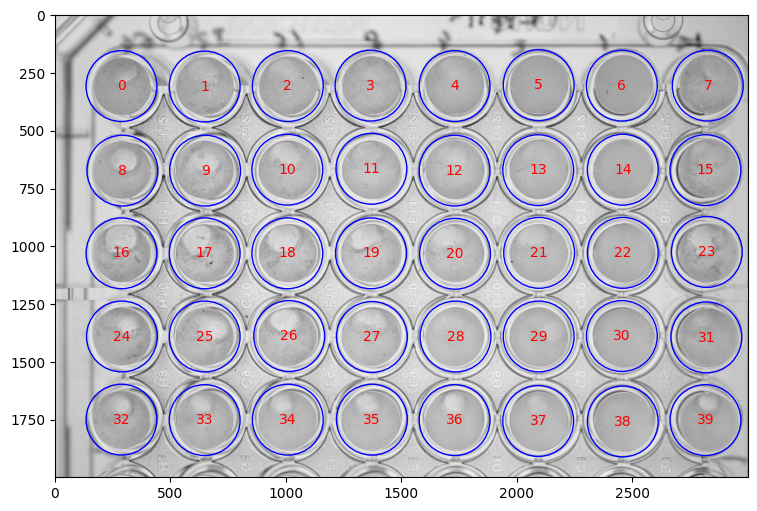

In [8]:
def plot_wells(image_np, centers, average_radius):
    fig, ax = plt.subplots(1, 1, figsize=(9, 6))
    ax.imshow(image_np, cmap="gray")
    for i, (xx, yy) in enumerate(centers):
        circ = Circle((xx, yy), average_radius, fill=False, color="blue")
        ax.add_patch(circ)
        ax.text(xx, yy, i,
                ha="center", va="center", color="red")


centers, average_radius = find_wells(image_np)
plot_wells(image_np, centers, average_radius)
# plot_image_projection(image_np=image_np)
# circles = plot_image_projection(image_np=ndi.gaussian_filter(image_np, sigma=0.1))

In [9]:
def make_well_masks(image_shape, centers, average_radius):
    mask = np.zeros((centers.shape[0],) + image_shape, dtype=np.uint8)
    for i, (xx, yy) in enumerate(centers):
        mask[i, :,:] = cv2.circle(np.zeros(image_shape), (int(xx), int(yy)), int(average_radius), 1, -1)
    return mask

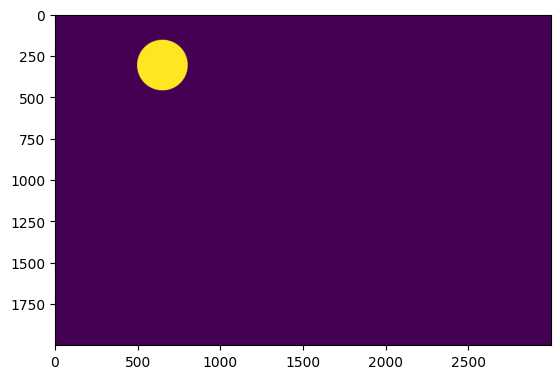

In [10]:
masks = make_well_masks(image_np.shape, centers, average_radius)
plt.imshow(masks[1])

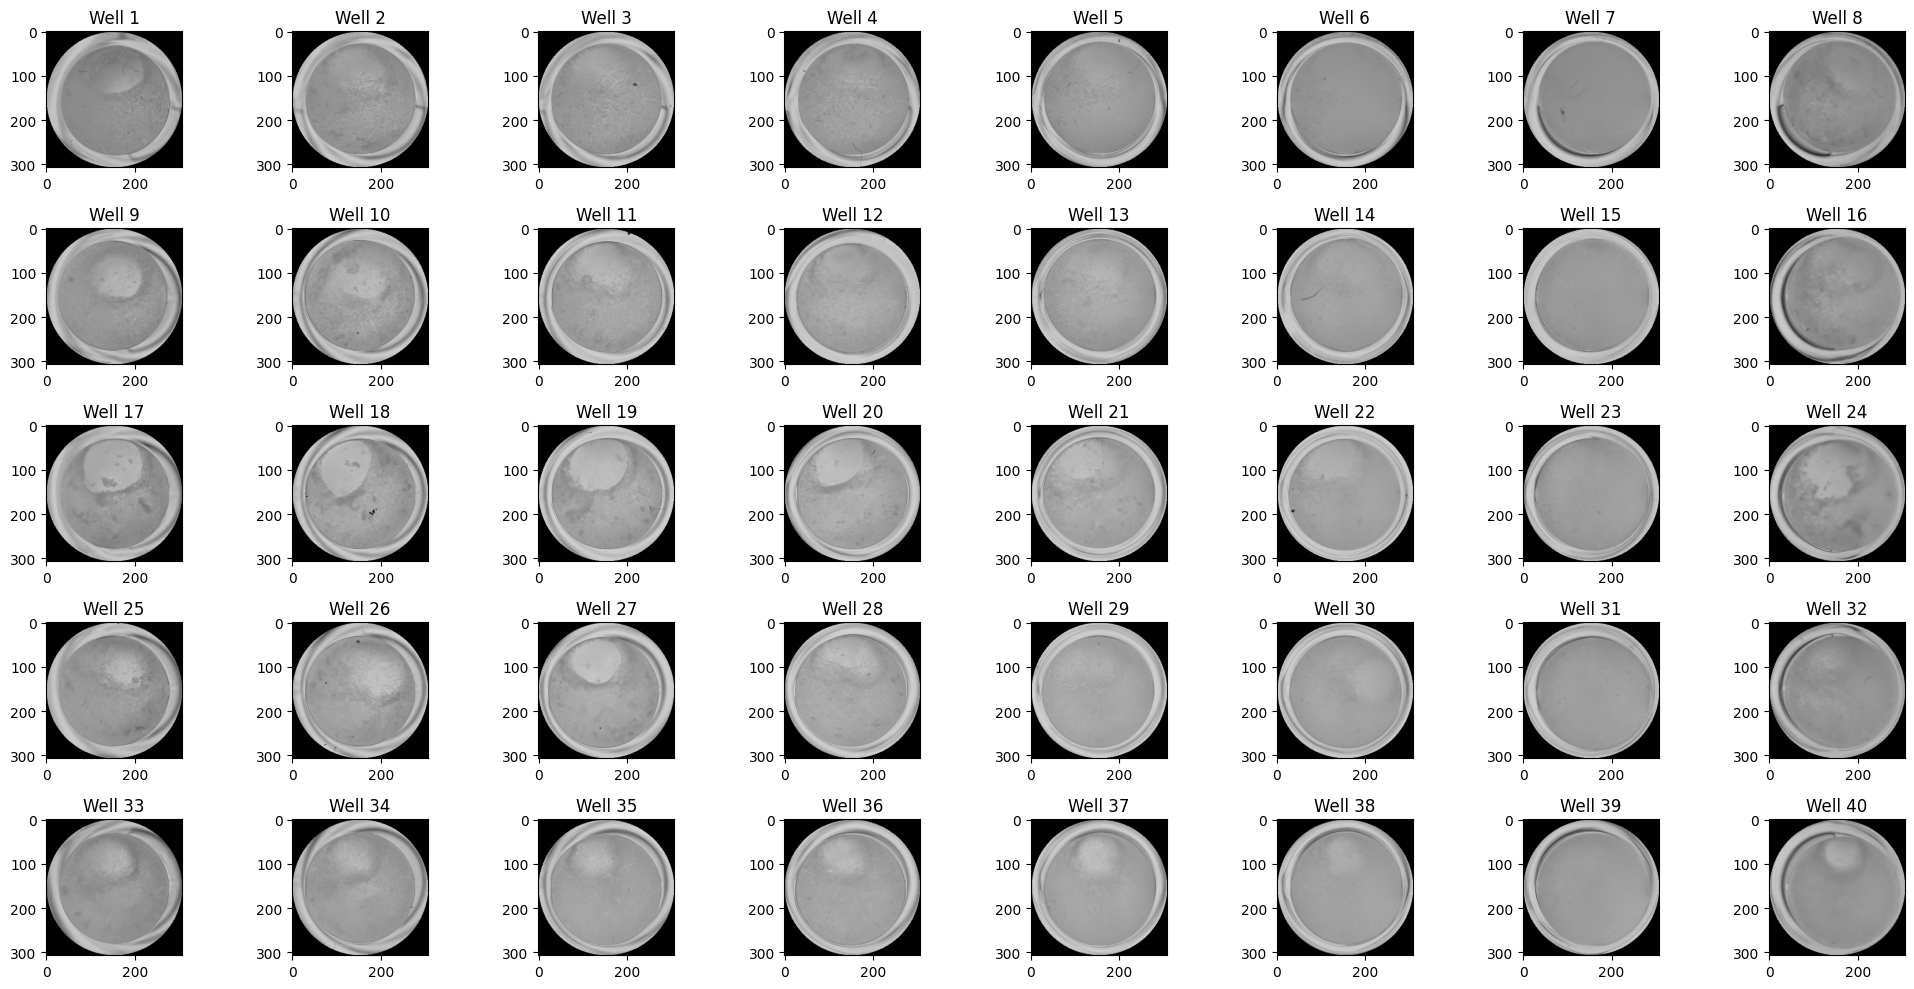

In [11]:
def get_well_images(image_np, centers, average_radius):
    masks = make_well_masks(image_np.shape, centers, average_radius)

    well_images = []
    well_masks = []
    for i, center in zip(range(masks.shape[0]), centers):
        well_image = image_np * masks[i]
        well_image = well_image[int(center[1] - average_radius):int(center[1] + average_radius),
                                int(center[0] - average_radius):int(center[0] + average_radius)]
        well_masks.append(masks[i][int(center[1] - average_radius):int(center[1] + average_radius),
                                   int(center[0] - average_radius):int(center[0] + average_radius)])
        well_images.append(well_image)
    return np.array(well_images), np.array(well_masks)


well_images, well_masks = get_well_images(image_np, centers, average_radius)

fig, axs = plt.subplots(5, 8, figsize=(20, 10))
for i, (ax, well_img, well_mask) in enumerate(zip(axs.flatten(), well_images, well_masks)):
    ax.imshow(well_img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Well {i+1}')
plt.tight_layout()
plt.show()

In [12]:
well_masks.shape

(40, 307, 307)

# Build dataset

In [13]:
import os
TARGET_SHAPE = 348

target_path = "dataset_segmentation"

In [16]:
import random

all_images = glob(DATASET_MASK)
all_images = random.sample(all_images, 20)
for image_path in tqdm(all_images):
    image_np = cv2.imread(image_path)
    image_np = cv2.cvtColor(image_np, cv2.COLOR_BGR2GRAY)

    centers, average_radius = find_wells(image_np)
    well_images, well_masks = get_well_images(
        image_np, centers, average_radius)
    for i in random.sample(range(well_images.shape[0]), 5):
        image = well_images[i]
        target_image_path = os.path.join(target_path, os.path.split(image_path)[
                                         1].replace('.JPG', f'_{i}.JPG'))

        border_size = TARGET_SHAPE - image.shape[0]
        if border_size % 2 == 1:
            top = border_size // 2
            bottom = top + 1
        else:
            top = bottom = border_size // 2

        image = cv2.copyMakeBorder(
            image, top, bottom, top, bottom, cv2.BORDER_CONSTANT, None, 0)
        cv2.imwrite(target_image_path, image)

  0%|          | 0/20 [00:00<?, ?it/s]